# Design a synthetic control before it runs

A synthetic-control analysis needs a post-period. A design check does not. If you already have a treated unit and a donor pool, you can fit the pre-period only and ask whether that pool can recover an effect you inject yourself. That is a dress rehearsal, not an estimate of a treatment that has not happened yet.

This notebook uses the first 40 rows of the built-in `sc` dataset as that pre-period. The sampling settings are intentionally short so the page stays runnable. They are not a production power study.


## Setup

The analysis notebook, [Bayesian synthetic control](synthetic-control-pymc.ipynb), shows how to estimate an effect once a post-period exists. The methods here are the pre-period counterparts: `SyntheticControl.from_pre_period`, `donor_pool_quality`, `validate_design`, and `power_analysis`.

::::{note}
These design methods require a PyMC model. A scikit-learn synthetic control can still be fit on the pre-period, but it cannot score a donor pool or run a dress rehearsal.
::::


In [1]:
import logging
import warnings

import pandas as pd
from IPython.display import display

import causalpy as cp

logging.getLogger("pymc").setLevel(logging.ERROR)
logging.getLogger("pytensor").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message="Only .* samples per chain")

seed = 42
sample_kwargs = {
    "draws": 20,
    "tune": 20,
    "chains": 1,
    "cores": 1,
    "progressbar": False,
    "random_seed": seed,
}

## Use only the pre-period

`from_pre_period` treats every supplied row as pre-period and places a pseudo treatment time one step after the last observation. The returned experiment is already fitted. `plot`, `get_plot_data`, and `effect_summary` raise `ValueError`, because there is no post window to plot.


In [2]:
panel = cp.load_data("sc").iloc[:40].copy()
panel.index = pd.date_range("2020-01-01", periods=len(panel), freq="D")
control_units = ["a", "b", "c", "d", "e", "f", "g"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    design = cp.SyntheticControl.from_pre_period(
        panel,
        control_units,
        ["actual"],
        model=cp.pymc_models.WeightedSumFitter(sample_kwargs=sample_kwargs),
    )
design.treatment_time, design.datapre.index.max(), len(design.datapost)

(Timestamp('2020-02-10 00:00:00'), Timestamp('2020-02-09 00:00:00'), 0)

The pseudo treatment time falls after the last pre-period date, and the post-period length is zero. That is the design-only contract: the fit exists so later methods can read pre-period residuals and donor weights, not so the figure can show an effect.


Donor-pool quality reports three pre-period facts. The correlation score is the mean correlation between the treated unit and each donor. An undefined correlation is omitted from that mean. Coverage is the share of pre-period times at which the treated value lies between the lowest and highest donor. That range check is necessary for a convex combination, but it is not the same claim as the whole path being one fixed-weight combination of the donors. Weight concentration is the effective number of donors implied by the posterior mean of `beta`. A value near 1 means one donor dominates {cite}`abadie2021using`.


In [3]:
pool = design.donor_pool_quality()
display(pool.summary())
display(
    pool.per_donor_details[["donor", "mean_correlation"]]
    .sort_values("mean_correlation")
    .reset_index(drop=True)
)

,metric,value,assessment
0,Mean donor correlation,0.717,acceptable
1,Convex hull coverage,100.0%,good
2,Effective number of donors,5.37,good
3,Overall quality,acceptable,acceptable


,donor,mean_correlation
0,g,-0.534925
1,d,0.775570
2,b,0.933276
3,a,0.933885
4,c,0.943970
5,e,0.976718
6,f,0.988235


The assessment labels are fixed package cuts, not a judgment this window invented. Correlation is good above 0.8 and acceptable above 0.5. Coverage is good above 0.95 and acceptable above 0.80. Effective donors are good above 3 and acceptable above 1.5. Overall quality is the worst of the three, which is why 100% coverage and 5.37 effective donors still leave the pool acceptable when the correlation is 0.717.

The donor table shows why. Unit `g` is negatively correlated with `actual` on these 40 days. The longer pre-period in the analysis notebook does not flag that unit, so the design window can change the donor decision. A poor coverage score means the treated series leaves the donor range. Change the pool before rehearsing. The rehearsal does not add donors, and a poor score is not by itself proof that an injected effect is unrecovered.


## Rehearse a known effect

`validate_design` holds out the last quarter of the pre-period, injects a known effect into that window, and refits. The reported recovery is the first treated unit's cumulative impact. Here the injected effect is a 15% increase, so the truth is 15% of that unit's held-out sum.

::::{important}
The HDI below uses 20 posterior draws. It shows how to read the result. It is not evidence that this donor pool recovers a 15% effect.
::::


In [4]:
rehearsal = design.validate_design(0.15, sample_kwargs=sample_kwargs)
rehearsal.summary()

,injected_effect,effect_type,injected_truth,recovered_effect_mean,hdi_lower,hdi_upper,hdi_covers_truth
0,0.15,relative,13.712959,15.999725,9.150655,21.440028,True


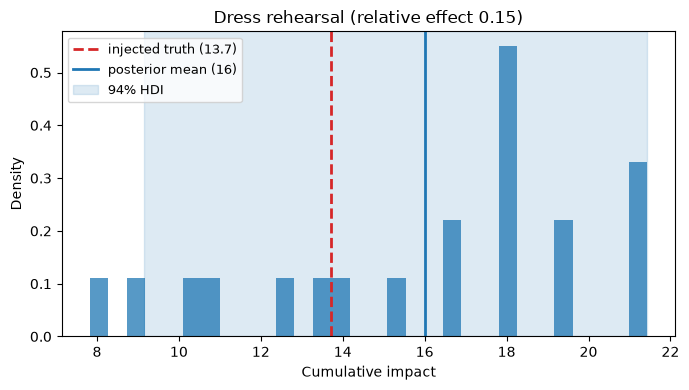

In [5]:
rehearsal.plot();

The title is the injected relative effect, 15%. The axis is that effect in outcome units: 15% of the held-out sum, 13.7. The dashed line is that injected truth. The solid line is the posterior mean of cumulative impact, 16 on this run. The band is the 94% HDI, about 9.2 to 21.4, and it covers 13.7. Coverage on 20 draws is a reading of this sample, not evidence that the donor pool recovers a 15% effect.


## Sketch a power curve

`power_analysis` repeats the dress rehearsal at each candidate effect size. Before each refit it adds iid Gaussian noise to the treated pre-period. The noise scale is the pre-period residual standard deviation of the first treated unit, and every treated unit receives that same draw.

::::{warning}
This is a heuristic, not a sampling distribution of the treatment effect. Independent Gaussian residuals ignore autocorrelation, seasonality, and heteroscedasticity. For a time-series donor pool the resulting detection rate can overstate power. Two simulations are enough to show the return type, not enough to choose an effect size.
::::


In [6]:
power = design.power_analysis(
    [0.05, 0.15],
    n_simulations=2,
    sample_kwargs=sample_kwargs,
    random_seed=seed,
)
power.summary()

,effect_size,detection_rate,mean_recovery,median_recovery,n_simulations
0,0.05,0.0,3.871508,3.871508,2
1,0.15,1.0,11.845683,11.845683,2


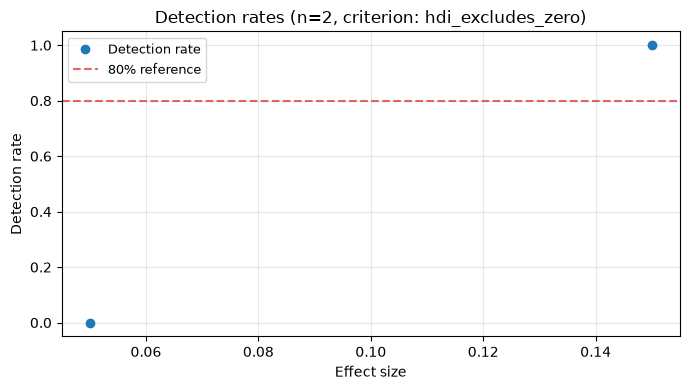

In [7]:
power.plot();

Each marker is a detection rate at that effect size: how many of the `n_simulations` rehearsals had a cumulative-impact HDI that excluded zero. The points are not joined, because two rates are not a power function. The dashed line at 0.8 is a plot reference, not a target this run estimated. The stored rates are 0 out of 2 and 2 out of 2. `mean_recovery` is the mean cumulative impact in outcome units, not the 5% or 15% effect. Short chains can diverge; a divergence on 20 draws is not a design verdict. Raise `n_simulations` and the MCMC length before comparing effect sizes. Pass `random_seed` in `sample_kwargs` as well as to `power_analysis` if the curve itself must be reproducible; the residual draws and the sampler do not share one seed.


## Summary

- Fit the design with `SyntheticControl.from_pre_period`. Do not plot that object.
- Read `donor_pool_quality()` before spending a dress rehearsal. Coverage asks whether the treated series stays inside the donor range at each time. A poor score is a reason to change the pool. It is not proof that an injected effect is unrecovered, and 100% coverage is not a convex combination of the whole path.
- Use `validate_design()` for one known effect and `power_analysis()` for rates across effect sizes.
- Treat the default curve as an iid Gaussian rehearsal. It does not model residual autocorrelation.
- Once the experiment has a post-period, switch to the [analysis notebook](synthetic-control-pymc.ipynb). `DressRehearsalCheck` can wrap `validate_design` in a sensitivity pipeline, but it is opt-in and refits the model.

## References

:::{bibliography}
:filter: docname in docnames
:::
